# t-SNE Tutorial: Visualizing High-Dimensional Data
## A Practical Guide to Understanding and Using t-SNE for Dimensionality Reduction

---

### What is t-SNE?

**t-SNE (t-Distributed Stochastic Neighbor Embedding)** is a machine learning technique for dimensionality reduction that is particularly good at visualizing high-dimensional data in 2D or 3D.

### Key Features:
- Non-linear dimensionality reduction
- Preserves local structure (keeps similar points close together)
- Great for visualization and exploratory data analysis
- Does NOT preserve global structure or distances

### When to Use t-SNE:
- Visualizing clusters in high-dimensional data
- Exploring data structure before modeling
- Understanding feature relationships
- Communicating patterns to non-technical audiences

### When NOT to Use t-SNE:
- Feature engineering (use PCA instead)
- Interpreting distances between clusters
- Statistical inference
- Very large datasets (it's slow)

In [ ]:
# Import required libraries
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.manifold import TSNE
from sklearn.preprocessing import StandardScaler
from sklearn.datasets import load_iris, load_digits
from sklearn.decomposition import PCA
import seaborn as sns

print("Libraries imported successfully!")
print("t-SNE Tutorial Ready")
print("=" * 70)

Libraries imported successfully!
t-SNE Tutorial Ready


---
## Example 1: Simple Iris Dataset (4 dimensions → 2 dimensions)

The Iris dataset is perfect for learning t-SNE because:
- Small and fast to compute
- Only 4 features (easy to understand)
- 3 clear classes (species)
- Well-known benchmark dataset

In [ ]:
# Load iris dataset - simple one containing 4 features
iris = load_iris()
X_iris = iris.data  # 4 features: sepal length, sepal width, petal length, petal width-> input composed of 4 features
y_iris = iris.target  # 3 species: setosa, versicolor, virginica - target - 3 clusters

print("Iris Dataset Information:")
print(f"Original data shape: {X_iris.shape}")
print(f"Features: {iris.feature_names}")
print(f"Classes: {iris.target_names}")
print(f"Number of samples per class: {np.bincount(y_iris)}")

Iris Dataset Information:
Original data shape: (150, 4)
Features: ['sepal length (cm)', 'sepal width (cm)', 'petal length (cm)', 'petal width (cm)']
Classes: ['setosa' 'versicolor' 'virginica']
Number of samples per class: [50 50 50]


In [ ]:
# Step 1: Standardize the data (VERY IMPORTANT!)
scaler = StandardScaler()
X_iris_scaled = scaler.fit_transform(X_iris)

print("Data standardized successfully")
print(f"Mean after scaling: {X_iris_scaled.mean(axis=0)}")
print(f"Std after scaling: {X_iris_scaled.std(axis=0)}")

Data standardized successfully
Mean after scaling: [-1.69031455e-15 -1.84297022e-15 -1.69864123e-15 -1.40924309e-15]
Std after scaling: [1. 1. 1. 1.]


In [ ]:
# Step 2: Apply t-SNE
print("Applying t-SNE...")
tsne = TSNE(n_components=2, random_state=42, perplexity=30, n_iter=1000) # create a variable then call TSNE and pass components, set perplexity parameter, iterations - low perplexity zooms every cluster - visualized as fragments - high perplexity tightly merges clusters together
X_iris_tsne = tsne.fit_transform(X_iris_scaled)

print(f"t-SNE complete!")
print(f"Original shape: {X_iris.shape}")# originally 4 columns
print(f"t-SNE output shape: {X_iris_tsne.shape}") # after tsne 2 columns - setting n_components = 2 to indicate number of dimensions
print(f"Reduced from {X_iris.shape[1]} dimensions to {X_iris_tsne.shape[1]} dimensions")

Applying t-SNE...


/usr/local/lib/python3.13/dist-packages/sklearn/manifold/_t_sne.py:1164: FutureWarning: 'n_iter' was renamed to 'max_iter' in version 1.5 and will be removed in 1.7.
  warnings.warn(


t-SNE complete!
Original shape: (150, 4)
t-SNE output shape: (150, 2)
Reduced from 4 dimensions to 2 dimensions


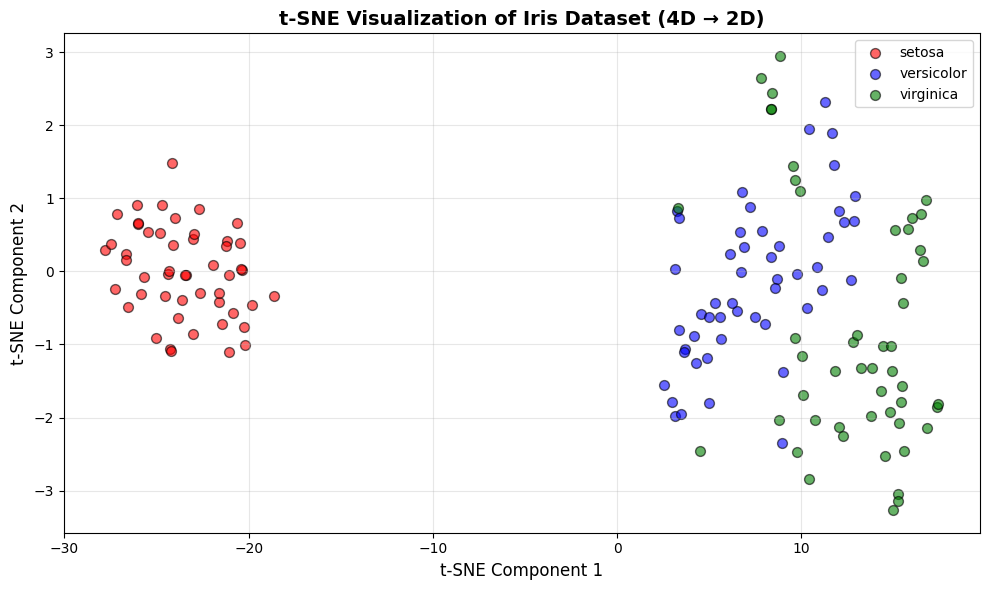

In [ ]:
# Step 3: Visualize t-SNE results
plt.figure(figsize=(10, 6))
colors = ['red', 'blue', 'green']

for i, target_name in enumerate(iris.target_names):
    mask = y_iris == i
    plt.scatter(X_iris_tsne[mask, 0],X_iris_tsne[mask, 1],
               c=colors[i], label=target_name, alpha=0.6, s=50, edgecolor='black')

plt.xlabel('t-SNE Component 1', fontsize=12)
plt.ylabel('t-SNE Component 2', fontsize=12)
plt.title('t-SNE Visualization of Iris Dataset (4D → 2D)', fontsize=14, fontweight='bold')
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

### Interpretation of Iris t-SNE:

- **3 distinct clusters** corresponding to the 3 iris species
- **Setosa** (red) is clearly separated - it's very different from the other two
- **Versicolor** (blue) and **Virginica** (green) overlap slightly - they're more similar
- t-SNE successfully reveals the natural grouping in the 4-dimensional data
- The 2D visualization preserves the relationships between similar flowers

---
## Example 2: Handwritten Digits (64 dimensions → 2 dimensions)

The Digits dataset is more challenging:
- 1797 samples of handwritten digits (0-9)
- 64 features (8×8 pixel images)
- 10 classes
- Higher dimensionality tests t-SNE's capabilities

In [ ]:
# Load digits dataset
digits = load_digits() # load dataset
X_digits = digits.data  # 8×8 pixel images = 64 features - each individual pixel acts as a single feature - .data=x
y_digits = digits.target  # Digits 0-9 - .target=y(label)

print("Digits Dataset Information:")
print(f"Original data shape: {X_digits.shape}")
print(f"Number of samples: {len(X_digits)}")
print(f"Number of features: {X_digits.shape[1]}")
print(f"Classes: {np.unique(y_digits)}")
print(f"Samples per class: {np.bincount(y_digits)}") # balanced dataset

Digits Dataset Information:
Original data shape: (1797, 64)
Number of samples: 1797
Number of features: 64
Classes: [0 1 2 3 4 5 6 7 8 9]
Samples per class: [178 182 177 183 181 182 181 179 174 180]


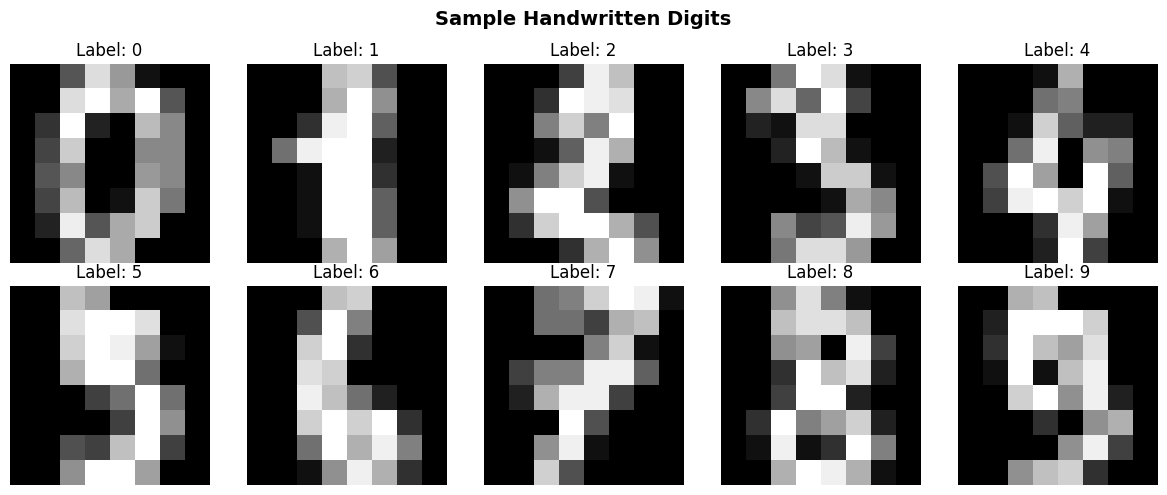

In [ ]:
# Visualize some sample digits
fig, axes = plt.subplots(2, 5, figsize=(12, 5))
for i, ax in enumerate(axes.flat):
    ax.imshow(digits.images[i], cmap='gray')
    ax.set_title(f'Label: {y_digits[i]}')
    ax.axis('off')
plt.suptitle('Sample Handwritten Digits', fontsize=14, fontweight='bold')
plt.tight_layout()
plt.show()

# Objective - visualize distribution of the digit - we have 64 dimensions which will be compressed to 2 dimensions and visualize it so we use tsne for this purpose
# Each digit represented by 8 pixels to represent digit we use an 8 by 8 pixel-64 features representation to recognize the digit whether its 0,1,2...

In [ ]:
# Use subset for faster computation (optional - use full dataset if you have time)
n_samples = 1000
np.random.seed(42)
indices = np.random.choice(len(X_digits), n_samples, replace=False)
X_subset = X_digits[indices]
y_subset = y_digits[indices]

print(f"Using {n_samples} samples for faster computation")
print(f"Subset shape: {X_subset.shape}")

Using 1000 samples for faster computation
Subset shape: (1000, 64)


In [ ]:
# Standardize the data- calculates distances to find neighbors within in local structure
# weight ->> some weights in kg/g- regardless of the example, all pixels in same range - u must standardize before preprocessing
scaler = StandardScaler()
X_subset_scaled = scaler.fit_transform(X_subset)

print("Data standardized")

Data standardized


In [ ]:
# Apply t-SNE (this may take 30-60 seconds)
print("Applying t-SNE to digits (this may take a minute)...")
# verbose-prints the steps - 1 means its true, other wise change it to 0 if u dont want it displayed
tsne_digits = TSNE(n_components=2, random_state=42, perplexity=30, n_iter=1000, verbose=1)
X_digits_tsne = tsne_digits.fit_transform(X_subset_scaled)

print("t-SNE complete!")

Applying t-SNE to digits (this may take a minute)...
[t-SNE] Computing 91 nearest neighbors...
[t-SNE] Indexed 1000 samples in 0.001s...
[t-SNE] Computed neighbors for 1000 samples in 0.059s...
[t-SNE] Computed conditional probabilities for sample 1000 / 1000
[t-SNE] Mean sigma: 2.688162


/usr/local/lib/python3.13/dist-packages/sklearn/manifold/_t_sne.py:1164: FutureWarning: 'n_iter' was renamed to 'max_iter' in version 1.5 and will be removed in 1.7.
  warnings.warn(


[t-SNE] KL divergence after 250 iterations with early exaggeration: 64.494011
[t-SNE] KL divergence after 1000 iterations: 0.698611
t-SNE complete!


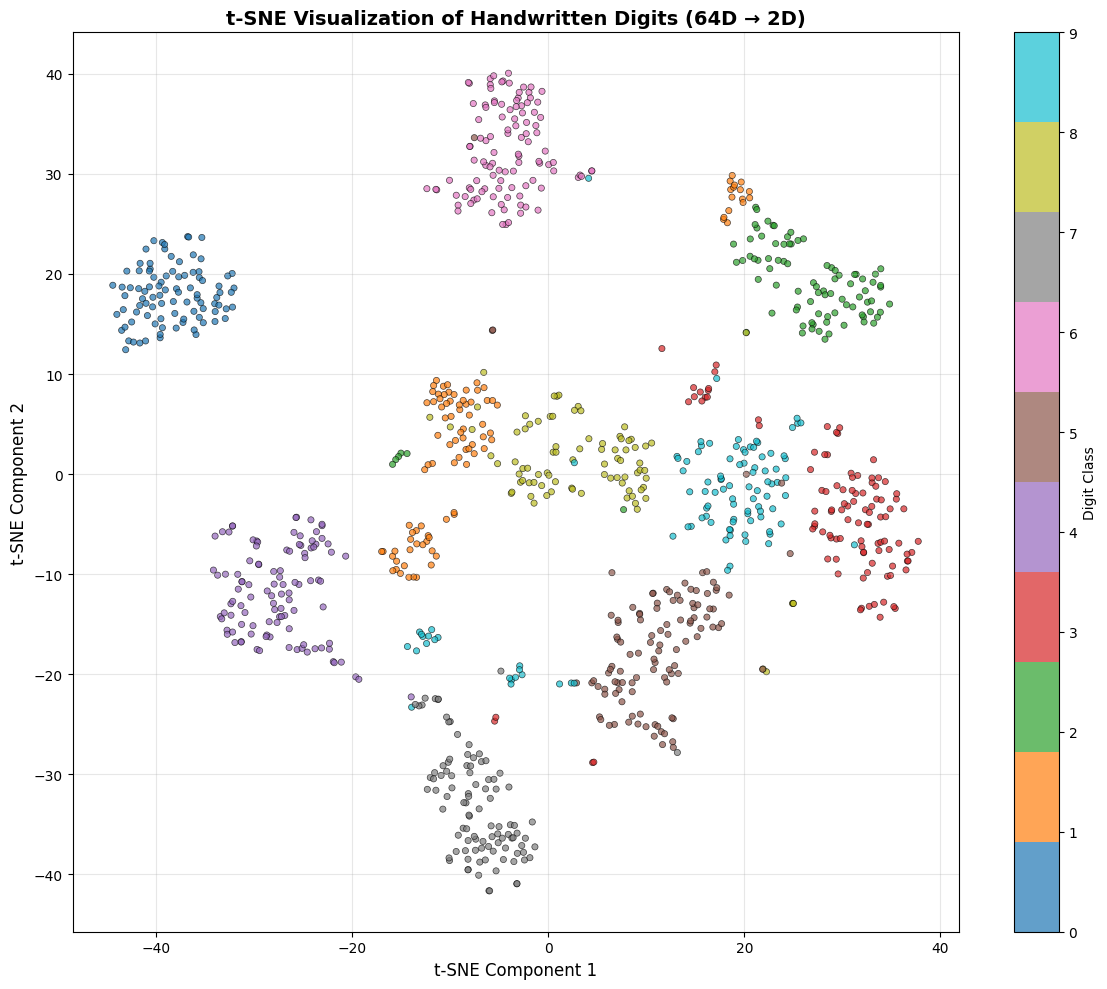

In [ ]:
# Visualize digits t-SNE
plt.figure(figsize=(12, 10))
scatter = plt.scatter(X_digits_tsne[:, 0], X_digits_tsne[:, 1],
                     c=y_subset, cmap='tab10', s=20, alpha=0.7,
                     edgecolor='black', linewidth=0.5)
plt.colorbar(scatter, label='Digit Class')
plt.xlabel('t-SNE Component 1', fontsize=12)
plt.ylabel('t-SNE Component 2', fontsize=12)
plt.title('t-SNE Visualization of Handwritten Digits (64D → 2D)',
          fontsize=14, fontweight='bold')
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()
# with perplexity we can distinguish globa; classes with some overlap between small points

### Interpretation of Digits t-SNE:

- **10 distinct clusters** - one for each digit (0-9)
- Some digits are well-separated (e.g., 0, 1)
- Some digits overlap (e.g., 4 and 9, 3 and 8) - they look visually similar
- The clustering reveals which digits are visually confusing- when we have overlap
- 64 dimensions compressed to 2D while preserving digit groupings
- Points within each cluster represent different handwriting styles of the same digit- confusion indicates diff handwriting styles that make digits confusing from others
- Indicates perplexity parameter is well set

---
## Example 3: Understanding t-SNE Parameters

### The Perplexity Parameter

**Perplexity** is the most important t-SNE parameter. It controls how many neighbors each point considers:
- **Low perplexity (5-10):** Focuses on very local structure, may create many small clusters
- **Medium perplexity (20-50):** Balanced view, recommended default is 30
- **High perplexity (50-100):** Considers more global structure, may merge distinct clusters

Let's see how different perplexity values affect the visualization:

Running t-SNE with perplexity=5...


/usr/local/lib/python3.13/dist-packages/sklearn/manifold/_t_sne.py:1164: FutureWarning: 'n_iter' was renamed to 'max_iter' in version 1.5 and will be removed in 1.7.
  warnings.warn(


Running t-SNE with perplexity=30...


/usr/local/lib/python3.13/dist-packages/sklearn/manifold/_t_sne.py:1164: FutureWarning: 'n_iter' was renamed to 'max_iter' in version 1.5 and will be removed in 1.7.
  warnings.warn(


Running t-SNE with perplexity=50...


/usr/local/lib/python3.13/dist-packages/sklearn/manifold/_t_sne.py:1164: FutureWarning: 'n_iter' was renamed to 'max_iter' in version 1.5 and will be removed in 1.7.
  warnings.warn(


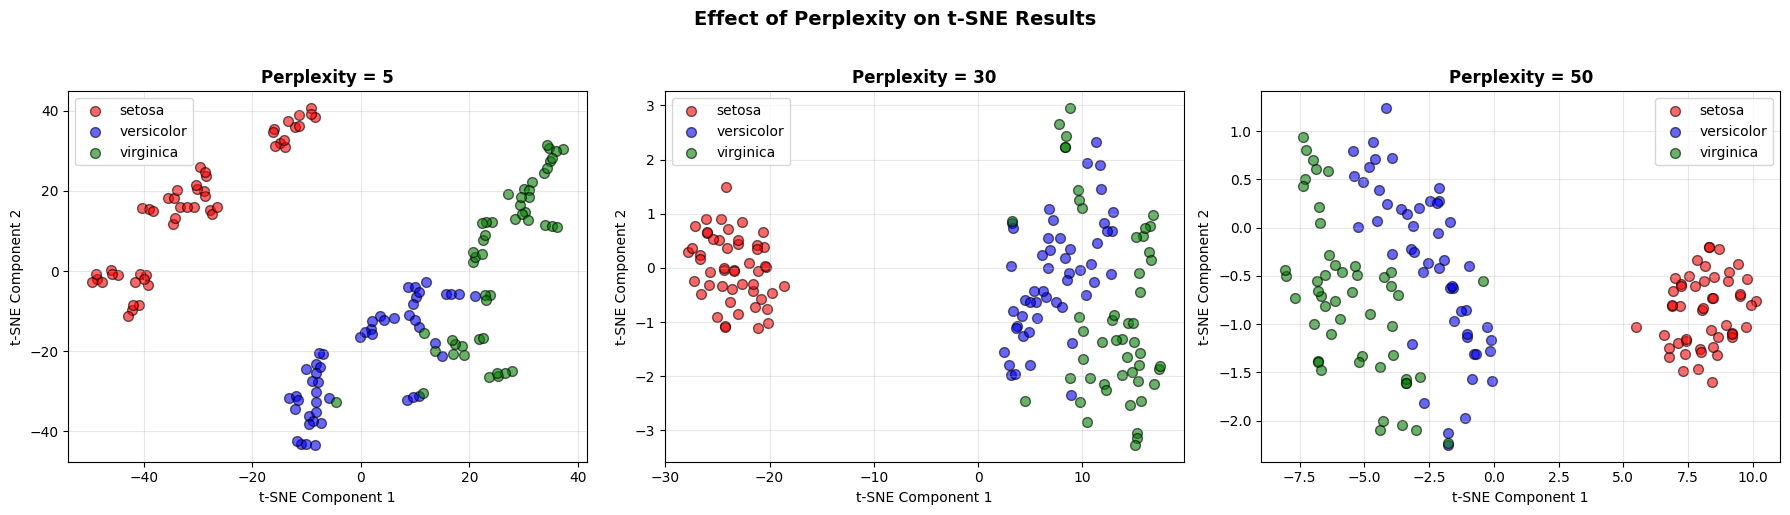

In [ ]:
# Test different perplexity values
perplexities = [5, 30, 50] # 30 and 50 cannot distinguish between blue and green - inc parameters merges some clusters
colors = ['red', 'blue', 'green']

fig, axes = plt.subplots(1, 3, figsize=(18, 5))
# for loop to go throufh all values of perplexity
for idx, perplexity in enumerate(perplexities):
    print(f"Running t-SNE with perplexity={perplexity}...")

    tsne = TSNE(n_components=2, random_state=42, perplexity=perplexity, n_iter=1000)
    X_tsne_temp = tsne.fit_transform(X_iris_scaled)# used for computational efficiency

    for i, target_name in enumerate(iris.target_names):
        mask = y_iris == i
        axes[idx].scatter(X_tsne_temp[mask, 0], X_tsne_temp[mask, 1],
                         c=colors[i], label=target_name, alpha=0.6, s=50, edgecolor='black')

    axes[idx].set_title(f'Perplexity = {perplexity}', fontsize=12, fontweight='bold')
    axes[idx].set_xlabel('t-SNE Component 1')
    axes[idx].set_ylabel('t-SNE Component 2')
    axes[idx].legend()
    axes[idx].grid(True, alpha=0.3)

plt.suptitle('Effect of Perplexity on t-SNE Results', fontsize=14, fontweight='bold', y=1.02)
plt.tight_layout()
plt.show()

# important - TSNE changes arrangement of data point are arbitrary - goal is to make groups from data putting together similar data points determined by perplexity parameter - getting different numbers in axes is meaningless we look at the grouping - only distance between neighboring points is preserved - unusal patterns/outliers will be determined
# dont look at the orientation or axes

### Observations:

- **Perplexity = 5:** May show tighter, more fragmented clusters
- **Perplexity = 30:** Balanced view with clear separation
- **Perplexity = 50:** May show broader, more merged patterns

**Recommendation:** Start with perplexity=30, then experiment with 5-50 range

---
## Example 4: t-SNE vs PCA Comparison

Let's compare t-SNE with PCA to understand their differences.

In [ ]:
# Apply PCA for comparison
pca = PCA(n_components=2)
X_iris_pca = pca.fit_transform(X_iris_scaled)

print(f"PCA explained variance: {pca.explained_variance_ratio_}")
print(f"Total variance explained: {pca.explained_variance_ratio_.sum():.2%}")

PCA explained variance: [0.72962445 0.22850762]
Total variance explained: 95.81%


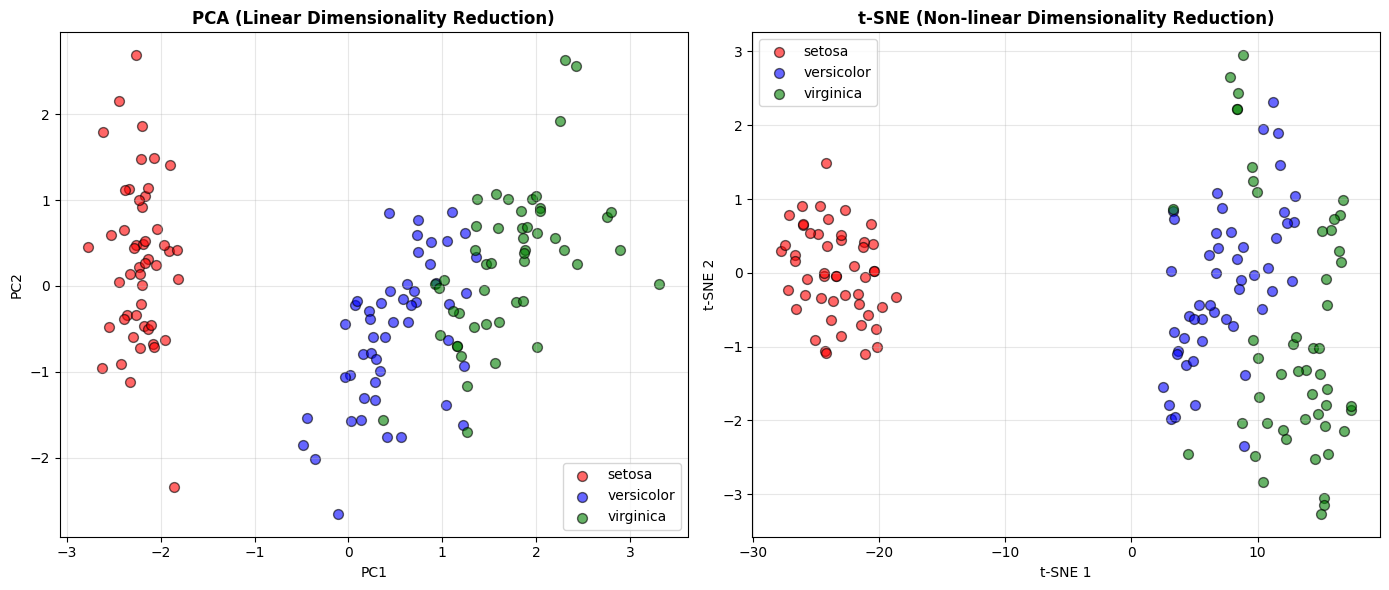

In [ ]:
# Compare visualizations side by side
fig, axes = plt.subplots(1, 2, figsize=(14, 6))
colors = ['red', 'blue', 'green']

# PCA plot
for i, target_name in enumerate(iris.target_names):
    mask = y_iris == i
    axes[0].scatter(X_iris_pca[mask, 0], X_iris_pca[mask, 1],
                   c=colors[i], label=target_name, alpha=0.6, s=50, edgecolor='black')
axes[0].set_title('PCA (Linear Dimensionality Reduction)', fontsize=12, fontweight='bold')
axes[0].set_xlabel('PC1')
axes[0].set_ylabel('PC2')
axes[0].legend()
axes[0].grid(True, alpha=0.3)

# t-SNE plot
for i, target_name in enumerate(iris.target_names):
    mask = y_iris == i
    axes[1].scatter(X_iris_tsne[mask, 0], X_iris_tsne[mask, 1],
                   c=colors[i], label=target_name, alpha=0.6, s=50, edgecolor='black')
axes[1].set_title('t-SNE (Non-linear Dimensionality Reduction)', fontsize=12, fontweight='bold')
axes[1].set_xlabel('t-SNE 1')
axes[1].set_ylabel('t-SNE 2')
axes[1].legend()
axes[1].grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

### PCA vs t-SNE: Key Differences

| Aspect | PCA | t-SNE |
|--------|-----|-------|
| **Type** | Linear | Non-linear |
| **Preserves** | Global structure, variance | Local structure, neighborhoods |
| **Speed** | Fast (seconds) | Slow (minutes) |
| **Deterministic** | Yes (same result every time) | No (random initialization) |
| **Interpretable** | Yes (components have meaning) | No (axes have no meaning) |
| **Use for** | Feature engineering, preprocessing | Visualization only |
| **Distance** | Meaningful between points | Not meaningful |
| **Clusters** | May overlap | Better separated |

### When to use which:
- **PCA:** Feature reduction, understanding variance, preprocessing for ML, feature engineering
- **t-SNE:** Exploratory visualization, finding clusters, presentations, understanding data structure

components in PCA is independent

---
## Best Practices and Tips

In [ ]:
print("=" * 70)
print("t-SNE BEST PRACTICES")
print("=" * 70)

best_practices = """
1. ALWAYS standardize your data first (use StandardScaler)
   - t-SNE is sensitive to feature scales
   - Ensures all features contribute equally

2. Choose appropriate perplexity:
   - Start with 30 (default)
   - Try range 5-50 for different perspectives
   - Higher perplexity for larger datasets
   - Rule: perplexity should be less than number of samples

3. Run multiple times with different random_state:
   - t-SNE has random initialization
   - Results can vary slightly between runs
   - Look for consistent patterns across runs

4. Increase n_iter if needed:
   - Default: 1000 iterations
   - Increase to 3000-5000 for complex datasets
   - Check if patterns stabilize

5. Don't use t-SNE for:
   - Measuring distances between clusters (not meaningful)
   - Feature engineering (use PCA instead)
   - Statistical testing
   - Clustering (cluster first, then visualize)

6. DO use t-SNE for:
   - Exploratory data analysis
   - Visualizing high-dimensional data
   - Communicating patterns to stakeholders
   - Understanding data structure
   - Finding potential clusters

7. Performance tips:
   - Use subset for large datasets (sample first)
   - Consider PCA preprocessing (reduce to 50 dims first)
   - Use parallel processing: n_jobs=-1 (if available)
   - Try faster implementations (openTSNE, MulticoreTSNE)

8. Interpretation tips:
   - Focus on cluster separation, not exact positions
   - Cluster sizes are not meaningful
   - Distances between clusters are not meaningful
   - Only local neighborhoods are preserved
"""

print(best_practices)

t-SNE BEST PRACTICES

1. ALWAYS standardize your data first (use StandardScaler)
   - t-SNE is sensitive to feature scales
   - Ensures all features contribute equally

2. Choose appropriate perplexity:
   - Start with 30 (default)
   - Try range 5-50 for different perspectives
   - Higher perplexity for larger datasets
   - Rule: perplexity should be less than number of samples

3. Run multiple times with different random_state:
   - t-SNE has random initialization
   - Results can vary slightly between runs
   - Look for consistent patterns across runs

4. Increase n_iter if needed:
   - Default: 1000 iterations
   - Increase to 3000-5000 for complex datasets
   - Check if patterns stabilize

5. Don't use t-SNE for:
   - Measuring distances between clusters (not meaningful)
   - Feature engineering (use PCA instead)
   - Statistical testing
   - Clustering (cluster first, then visualize)

6. DO use t-SNE for:
   - Exploratory data analysis
   - Visualizing high-dimensional data
   - 

---
## Exercise: Apply t-SNE to Your Own Data

Now it's your turn! Use the template below to apply t-SNE to your wildfire dataset or any other dataset.

---
## Summary

### What We Learned:

1. **t-SNE Basics:** Non-linear dimensionality reduction for visualization
2. **How to use it:** Standardize → Apply t-SNE → Visualize
3. **Parameters:** Perplexity controls local vs global structure
4. **vs PCA:** t-SNE is non-linear and better for visualization, PCA is linear and better for feature engineering
5. **Best practices:** Always standardize, try multiple perplexity values, run multiple times

### Key Takeaways:

- t-SNE is powerful for **visualizing** high-dimensional data
- It reveals **clusters and patterns** that are hard to see in original dimensions
- It's **not suitable** for feature engineering or measuring distances
- Always **standardize** your data first
- **Experiment** with parameters to find the best visualization

### Further Reading:

- Original paper: "Visualizing Data using t-SNE" by van der Maaten & Hinton (2008)
- Interactive explanation: https://distill.pub/2016/misread-tsne/
- sklearn documentation: https://scikit-learn.org/stable/modules/generated/sklearn.manifold.TSNE.html

---

**Happy exploring with t-SNE!** 🎨📊